In [50]:
import pandas as pd
import os
import requests
import numpy as np
import config
import subprocess
from io import StringIO
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from pathlib import Path
import statsmodels.api as sm
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_poisson_deviance

from get_elo import update_elo_history
from fixture_loader import load_fixtures, both_prem

In [51]:
%load_ext autoreload
%autoreload 2

GIT_REPO = os.path.expanduser("~/MyProjects/FPL/FPL-Elo-Insights")
subprocess.run(["git", "-C", GIT_REPO, "pull"], check=True)

def get_gw_state():    
    return requests.get("https://draft.premierleague.com/api/game").json()
    
state = get_gw_state()
GW = state["next_event"]
LAST_GW = GW - 1
TOTAL_MINUTES = GW * 90

last_year_stats = pd.read_excel("seasons/2025-26/End2526_Full.xlsx")

FPL_DATA_FOLDER = os.path.expanduser('~/MyProjects/FPL/FPL-Elo-Insights/data/2026-2027')
PREV_DATA_FOLDER = os.path.expanduser('~/MyProjects/FPL/FPL-Elo-Insights/data/2025-2026')

fixtures_dir = os.path.join(FPL_DATA_FOLDER, "By Gameweek")
prev_dir     = os.path.join(PREV_DATA_FOLDER, "By Gameweek")

players = pd.read_csv(f"{FPL_DATA_FOLDER}/players.csv",encoding="utf-8")
teams = pd.read_csv(f"{FPL_DATA_FOLDER}/teams.csv",encoding="utf-8")
prev_teams = pd.read_csv(f"{PREV_DATA_FOLDER}/teams.csv", encoding="utf-8")

playerstats = pd.read_csv(f"{FPL_DATA_FOLDER}/By Gameweek/GW{LAST_GW}/playerstats.csv",encoding="utf-8")

elo_hist = update_elo_history(GW)
elo = elo_hist[elo_hist["date"] == elo_hist["date"].max()].set_index("code")["elo"]

fixtures_master = load_fixtures(fixtures_dir)
prev_fx         = load_fixtures(prev_dir, played_only=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Already up to date.


In [52]:
#### PLAYER STATS BASE

# 1. playerstats + players (get names, position, team_code)
merged = playerstats.merge(
    players,
    left_on="id",
    right_on="player_id",
    how="left",
    suffixes=("", "_p")      # keep playerstats names clean, suffix player dups
)

# 2. + teams (get team short_name)
merged = merged.merge(
    teams[["code", "short_name"]],
    left_on="team_code",
    right_on="code",
    how="left"
).rename(columns={"short_name": "team_name"}).drop(columns=["code"])

TRANSFERRED_OUT = {"Woltemade", "Beto", "Sánchez"} 
print(merged[merged["web_name"].isin(TRANSFERRED_OUT)][["id", "web_name", "team_name"]])

merged = merged[~merged["web_name"].isin(TRANSFERRED_OUT)].copy()

base_cols = [
    # --- identity ---
    "web_name",
    "position",
    "team_name",

    # --- core output / value ---
    "total_points",
    "points_per_game",
    "minutes",
    "starts",
    "bonus",
    "bps",
    "form",

    # --- expected (xG) ---
    "expected_goals_per_90",
    "expected_assists_per_90",
    "expected_goal_involvements_per_90",
    "expected_goals_conceded_per_90",

    # --- defcon ---
    "defensive_contribution",
    "defensive_contribution_per_90",
    "tackles",
    "clearances_blocks_interceptions",
    "recoveries",

    # --- set pieces ---
    "penalties_order",
    "corners_and_indirect_freekicks_order",
    "direct_freekicks_order",

    # --- gk-specific ---
    "saves_per_90",
    "clean_sheets_per_90",
    "goals_conceded_per_90",

    # meta
    "player_id",
    "team_code",

    # --- availability ---
    "status",
    "chance_of_playing_next_round"
]

base = merged[base_cols].copy()

base = base.sort_values(by='total_points', ascending=False)

      id   web_name team_name
188  140    Sánchez       CHE
309  248       Beto       EVE
558  463  Woltemade       NEW


In [53]:
### FORM SCORE

FORM_WEIGHTS = [0.5, 0.3, 0.2]          # last game first
STAT_MAP = {"expected_goal_involvements": "form_xgi", "bonus": "form_bps",
            "defensive_contribution": "form_defcon", "event_points": "form_points",
            "goals_conceded": "form_gc", "minutes": "form_minutes"}

def compute_form_score(row):
    if row["position"] == "Forward":
        return (
            0.45 * row["form_points_p90"] +
            0.45 * row["form_xgi_p90"] +
            0.10 * row["form_bps_p90"] 
        )
    elif row["position"] == "Midfielder":
        return (
            0.40 * row["form_points_p90"] +
            0.25 * row["form_xgi_p90"] +
            0.10 * row["form_bps_p90"] +
            0.25 * row["form_defcon_p90"]
        )
    elif row["position"] == "Defender":
        return (
            0.40 * row["form_points_p90"] +
            0.10 * row["form_bps_p90"] +
            0.25 * row["form_defcon_p90"] +
            0.10 * row["form_xgi_p90"] -
            0.15 * row["form_gc_p90"] 
        )
    else:  # Goalkeeper
        return (
            0.10 * row["form_bps_p90"] +
            0.40 * row["form_points_p90"] -
            0.50 * row["form_gc_p90"]
        )

def build_form(GW, data_folder, weights=FORM_WEIGHTS, min_weighted_minutes=30):
    files = [(GW - k, w) for k, w in enumerate(weights, start=1)
             if GW - k >= 1 and os.path.exists(f"{data_folder}/By Gameweek/GW{GW - k}/player_gameweek_stats.csv")]
    total = sum(w for _, w in files)
    frames = []
    for gw, w in files:
        d = pd.read_csv(f"{data_folder}/By Gameweek/GW{gw}/player_gameweek_stats.csv", encoding="utf-8")
        for src, dst in STAT_MAP.items():
            d[dst] = d[src] * (w / total)
        frames.append(d[["id"] + list(STAT_MAP.values())])
    fs = pd.concat(frames).groupby("id", as_index=False).sum()
    mins = fs["form_minutes"].clip(lower=min_weighted_minutes)
    for c in ["form_points", "form_gc", "form_xgi", "form_bps", "form_defcon"]:
        fs[f"{c}_p90"] = fs[c] / mins * 90
    return fs

form_summary = build_form(GW, FPL_DATA_FOLDER)

print([c for c in merged.columns if c in ("id", "player_id")])

merged = merged.merge(form_summary.rename(columns={"id": "player_id"}),
                      on="player_id", how="left")

print(merged["form_minutes"].isna().sum())
merged["form_score"] = merged.apply(compute_form_score, axis=1) 



['id', 'player_id']
0


In [54]:
### FIXTURE ORGANIZATION
this_seasons_fixtures    = load_fixtures(fixtures_dir)
fixtures_master = both_prem(this_seasons_fixtures, teams)
prev_fx         = both_prem(load_fixtures(prev_dir, played_only=True), prev_teams)

print(fixtures_master["tournament"].value_counts())
print(fixtures_master.groupby(["gameweek", "home_team"]).size().max())
print(prev_fx["tournament"].value_counts())

tournament
prem       380
efl-cup     13
Name: count, dtype: int64
2
tournament
prem             380
efl-cup           16
europa-league      2
Name: count, dtype: int64


In [55]:
# #### FIXTURE GAMBLER MACHINE LEARNING MODEL

## LAST SEASON
prev_fx = prev_fx[prev_fx["tournament"].str.lower().str.contains("prem")].copy()
print(prev_fx.shape)

## CURRENT SEASON
fixtures_master = this_seasons_fixtures[
    this_seasons_fixtures["tournament"].str.lower().str.contains("prem")].copy()

# ELO going INTO each GW:  (GW1-6 backfilled, estimated) + scraped history (GW7+)

elo_all = pd.concat([pd.read_csv("data/elo_backfill.csv"),
                     pd.read_csv("data/elo_history.csv")])
elo_all = elo_all.drop_duplicates(["gw", "code"], keep="last")

elo_long = (elo_all.pivot(index="gw", columns="code", values="elo")
            .reindex(range(1, 39)).ffill() 
            .stack())

for s in ["home", "away"]:
    idx = pd.MultiIndex.from_arrays([fixtures_master["gameweek"], fixtures_master[f"{s}_team"]])
    fixtures_master[f"{s}_team_elo"] = elo_long.reindex(idx).values

# fixtures_master["elo_diff"] = fixtures_master["home_team_elo"] - fixtures_master["away_team_elo"]
# fixtures_master["elo_context"] = fixtures_master["elo_diff"] / 250

def team_view(df, me, opp, is_home):
    return pd.DataFrame({
        "gameweek": df["gameweek"], "team": df[f"{me}_team"], "opp": df[f"{opp}_team"], "is_home": is_home,
        "elo": df[f"{me}_team_elo"],
        "goals_scored": df[f"{me}_score"],          "goals_conceded": df[f"{opp}_score"],
        "non_penalty_xg": df[f"{me}_non_penalty_xg"], "non_penalty_xg_allowed": df[f"{opp}_non_penalty_xg"],
        "xg_set_play": df[f"{me}_xg_set_play"],       "xg_set_play_allowed": df[f"{opp}_xg_set_play"],
        "xg_on_target_xgot": df[f"{me}_xg_on_target_xgot"], "xg_on_target_xgot_allowed": df[f"{opp}_xg_on_target_xgot"],
        "keeper_saves": df[f"{me}_keeper_saves"]})

def build_team_table(fx, gw):
    played = fx[fx["gameweek"] <= gw].copy()
    played["elo_context"] = (played["home_team_elo"] - played["away_team_elo"]) / 250

    team_fixtures = (pd.concat([team_view(played, "home", "away", 1), team_view(played, "away", "home", 0)],
                               ignore_index=True).sort_values(["team", "gameweek"]))

    team_fixtures["finishing_xgot_over"] = team_fixtures["xg_on_target_xgot"] - team_fixtures["non_penalty_xg"]
    team_fixtures["shot_stopping_diff"]  = team_fixtures["xg_on_target_xgot_allowed"] - team_fixtures["goals_conceded"]
    team_fixtures["keeper_intensity"]    = team_fixtures["keeper_saves"] / team_fixtures["xg_on_target_xgot_allowed"].clip(lower=0.1)
    team_fixtures["open_play_xg"]         = team_fixtures["non_penalty_xg"] - team_fixtures["xg_set_play"]
    team_fixtures["open_play_xg_allowed"] = team_fixtures["non_penalty_xg_allowed"] - team_fixtures["xg_set_play_allowed"]

    def ewm(col, by=("team",), hl=6):
        return (team_fixtures.groupby(list(by))[col]
                .transform(lambda s: s.shift(1).ewm(halflife=hl, min_periods=1).mean()))

    for c in ["xg_set_play", "xg_set_play_allowed", "open_play_xg", "open_play_xg_allowed"]:
        team_fixtures[f"ewm_{c}"] = ewm(c)
    for src, name in [("finishing_xgot_over", "finishing_over"),
                      ("shot_stopping_diff", "shot_stopping"),
                      ("keeper_intensity", "keeper_intensity")]:
        team_fixtures[f"ewm_{name}"] = ewm(src, ("team", "is_home")).fillna(0)
    
    def blend(c): return team_fixtures[f"ewm_{c}"]

    team_fixtures["weighted_set_play_strength"]  = blend("xg_set_play")
    team_fixtures["weighted_open_play_strength"] = blend("open_play_xg")
    team_fixtures["weighted_set_play_defence"]   = -blend("xg_set_play_allowed")
    team_fixtures["weighted_open_play_defence"]  = -blend("open_play_xg_allowed")
    team_fixtures["weighted_attack"] = (
        0.60 * blend("open_play_xg") + 0.30 * blend("xg_set_play") + 0.10 * blend("finishing_over"))
    team_fixtures["weighted_defence"] = (
        -0.60 * blend("open_play_xg_allowed") - 0.30 * blend("xg_set_play_allowed")
        + 0.10 * blend("shot_stopping"))

    return played, team_fixtures

def add_diffs(played, team_fixtures):
    def side_feats(is_home, prefix):
        f = (team_fixtures[team_fixtures["is_home"] == is_home]
             .rename(columns=lambda c: prefix + c if c not in ["gameweek", "team", "opp", "is_home"] else c))
        return f[["gameweek", "team", "opp"] + [c for c in f.columns if c.startswith(prefix + "weighted")]]

    played = played.merge(side_feats(1, "home_"),
                          left_on=["gameweek", "home_team", "away_team"],
                          right_on=["gameweek", "team", "opp"],
                          how="left").drop(columns=["team", "opp"])
    played = played.merge(side_feats(0, "away_"),
                          left_on=["gameweek", "away_team", "home_team"],
                          right_on=["gameweek", "team", "opp"],
                          how="left").drop(columns=["team", "opp"])

    played["set_play_diff"] = (
        (played["home_weighted_set_play_strength"] - played["away_weighted_set_play_defence"]) -
        (played["away_weighted_set_play_strength"] - played["home_weighted_set_play_defence"]))

    played["open_play_diff"] = (
        (played["home_weighted_open_play_strength"] - played["away_weighted_open_play_defence"]) -
        (played["away_weighted_open_play_strength"] - played["home_weighted_open_play_defence"]))

    played["attack_diff"] = (
        (played["home_weighted_attack"] - played["away_weighted_defence"]) -
        (played["away_weighted_attack"] - played["home_weighted_defence"]))

    return played.sort_values("gameweek")

played, team_fixtures = build_team_table(fixtures_master, GW)
prev_played, prev_team_fixtures = build_team_table(prev_fx, 38)

played      = add_diffs(played, team_fixtures)
prev_played = add_diffs(prev_played, prev_team_fixtures)

latest = team_fixtures.sort_values("gameweek").groupby("team").tail(1)
latest = latest.merge(teams[["code","short_name"]], left_on="team", right_on="code", how="left")

print(latest[["short_name","weighted_attack"]].sort_values("weighted_attack", ascending=False).round(2).to_string(index=False))
print(latest[["short_name","weighted_defence"]].sort_values("weighted_defence", ascending=False).round(2).to_string(index=False))
print(latest[["short_name","elo"]].sort_values("elo", ascending=False).to_string(index=False))
print(fixtures_master[["home_team_elo","away_team_elo"]].isna().sum())



(380, 103)
short_name  weighted_attack
       MCI             1.26
       BOU             1.06
       BHA             1.05
       ARS             0.90
       FUL             0.80
       AVL             0.78
       MUN             0.77
       IPS             0.77
       CHE             0.76
       NFO             0.75
       LIV             0.73
       CRY             0.71
       BRE             0.66
       LEE             0.66
       EVE             0.66
       SUN             0.58
       COV             0.55
       NEW             0.54
       TOT             0.53
       HUL             0.50
short_name  weighted_defence
       ARS             -0.36
       NFO             -0.59
       BHA             -0.59
       TOT             -0.60
       MCI             -0.62
       LIV             -0.63
       BOU             -0.65
       MUN             -0.69
       FUL             -0.69
       CHE             -0.70
       HUL             -0.72
       EVE             -0.72
       LEE             -

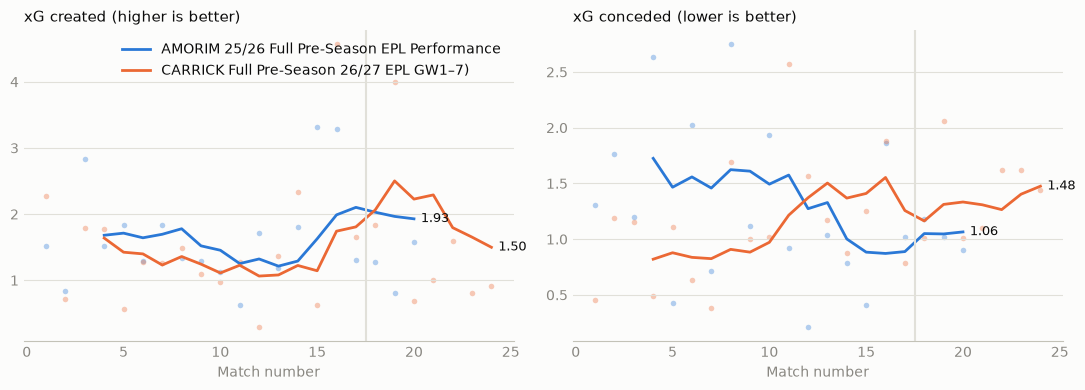

CARRICK (GW22-38 last season + GW1-7 this season)


    gameweek   opp  goals_scored  goals_conceded  non_penalty_xg  \
0       22.0  43.0           2.0             0.0            2.27   
1       23.0   3.0           3.0             2.0            0.71   
2       24.0  54.0           3.0             2.0            1.79   
3       25.0   6.0           2.0             0.0            1.78   
4       26.0  21.0           1.0             1.0            0.57   
5       27.0  11.0           1.0             0.0            1.27   
6       28.0  31.0           2.0             1.0            1.26   
7       29.0   4.0           1.0             2.0            1.48   
8       30.0   7.0           3.0             1.0            1.10   
9       31.0  91.0           2.0             2.0            0.98   
10      32.0   2.0           1.0             2.0            1.27   
11      33.0   8.0           1.0             0.0            0.29   
12      34.0  94.0           2.0             1.0            1.36

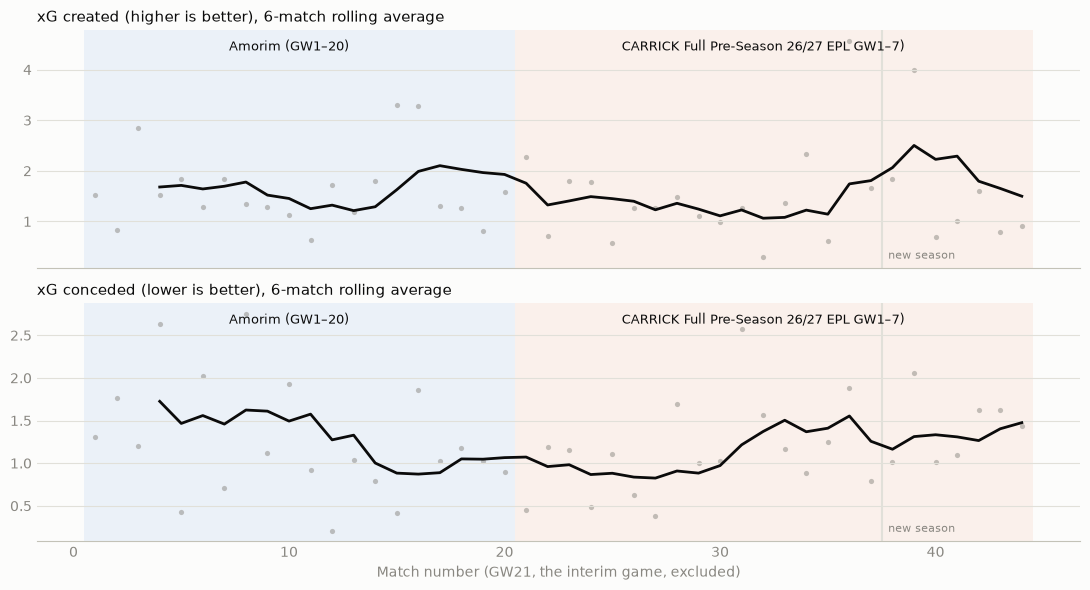

         non_penalty_xg  non_penalty_xg_allowed  goals_scored  goals_conceded
mgr                                                                          
Amorim             1.62                    1.26          1.65            1.45
Carrick            1.51                    1.21          1.79            1.17


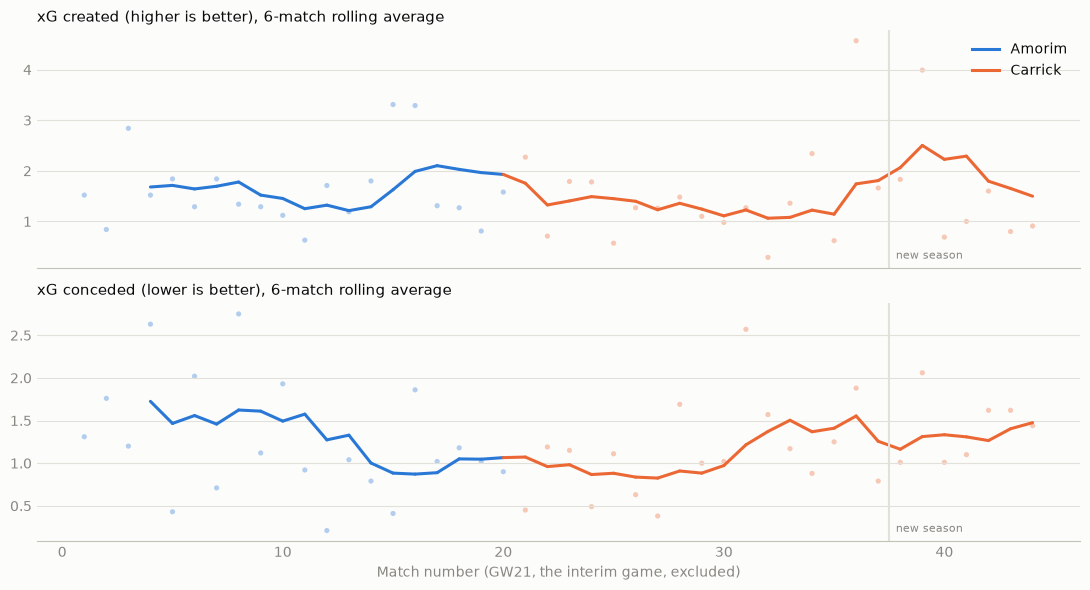

In [56]:
import matplotlib.pyplot as plt

code = teams.loc[teams["short_name"] == "MUN", "code"].iloc[0]

def mun(tf, gw_from, gw_to):
    return (tf[(tf["team"] == code) & tf["gameweek"].between(gw_from, gw_to)]
            .dropna(subset=["non_penalty_xg"])
            .sort_values("gameweek").reset_index(drop=True))

last      = mun(prev_team_fixtures, 1, 20)                      # first manager
this_prev = mun(prev_team_fixtures, 22, 38)                     # second manager, last season
this_now  = mun(team_fixtures, 1, 7)                            # second manager, this season

this = pd.concat([this_prev, this_now], ignore_index=True)
for d in (last, this):
    d["game"] = d.index + 1

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, facecolor="#fcfcfb")
panels = [("non_penalty_xg", "xG created (higher is better)"),
          ("non_penalty_xg_allowed", "xG conceded (lower is better)")]

for ax, (col, title) in zip(axes, panels):
    ax.set_facecolor("#fcfcfb")
    for d, color, label in [(last, BLUE, "AMORIM 25/26 Full Pre-Season EPL Performance"),
                            (this, ORANGE, "CARRICK Full Pre-Season 26/27 EPL GW1–7)")]:
        ax.scatter(d["game"], d[col], s=16, color=color, alpha=0.35, linewidths=0)
        avg = d[col].rolling(6, min_periods=4).mean()                                         # season-to-date average
        ax.plot(d["game"], avg, color=color, lw=2, label=label)
        ax.annotate(f"{avg.iloc[-1]:.2f}", (d["game"].iloc[-1], avg.iloc[-1]),
                    xytext=(5, 0), textcoords="offset points", color=INK, fontsize=9, va="center")
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("Match number", color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.axvline(len(this_prev) + 0.5, color=GRID, lw=1.5)   # summer gap
    ax.tick_params(colors=MUTED, length=0)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")

axes[0].legend(frameon=False, loc="upper right", labelcolor=INK)
plt.tight_layout()
plt.show()

cols = ["gameweek", "opp", "goals_scored", "goals_conceded",
        "non_penalty_xg", "non_penalty_xg_allowed"]
print("CARRICK (GW22-38 last season + GW1-7 this season)")
print('\n')
print(this[cols].round(2))
print(this[cols[2:]].mean().round(2))
print("\nAMORIM 25/26 Full Pre-Season EPL Performance")
print('\n')
print(last.head(7)[cols[2:]].mean().round(2))

W = 6   # rolling window; try 4 and 8 to check what holds up

amorim  = mun(prev_team_fixtures, 1, 20).assign(mgr="Amorim")
carrick = pd.concat([mun(prev_team_fixtures, 22, 38),
                     mun(team_fixtures, 1, 7)], ignore_index=True).assign(mgr="Carrick")

allg = pd.concat([amorim, carrick], ignore_index=True)
allg["game"] = allg.index + 1

n_a      = len(amorim)                 # end of Amorim's run
n_season = n_a + len(carrick) - 7      # last match of last season
N        = len(allg)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, facecolor="#fcfcfb")
panels = [("non_penalty_xg", "xG created (higher is better)"),
          ("non_penalty_xg_allowed", "xG conceded (lower is better)")]

for ax, (col, title) in zip(axes, panels):
    ax.set_facecolor("#fcfcfb")
    ax.axvspan(0.5, n_a + 0.5, color=BLUE, alpha=0.08, lw=0)
    ax.axvspan(n_a + 0.5, N + 0.5, color=ORANGE, alpha=0.08, lw=0)
    ax.axvline(n_season + 0.5, color=GRID, lw=1.5)                       # summer break

    ax.scatter(allg["game"], allg[col], s=14, color=MUTED, alpha=0.5, linewidths=0)
    roll = allg[col].rolling(W, min_periods=4).mean()
    ax.plot(allg["game"], roll, color=INK, lw=2)

    tr = ax.get_xaxis_transform()
    ax.text(n_a / 2, 0.96, "Amorim (GW1–20)", transform=tr, ha="center", va="top", color=INK, fontsize=9)
    ax.text((n_a + N) / 2, 0.96, "CARRICK Full Pre-Season 26/27 EPL GW1–7)", transform=tr,
            ha="center", va="top", color=INK, fontsize=9)
    ax.text(n_season + 0.8, 0.04, "new season", transform=tr, color=MUTED, fontsize=8)

    ax.set_title(f"{title}, {W}-match rolling average", loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.tick_params(colors=MUTED, length=0)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")

axes[1].set_xlabel("Match number (GW21, the interim game, excluded)", color=MUTED)
plt.tight_layout()
plt.show()

print(allg.groupby("mgr")[["non_penalty_xg", "non_penalty_xg_allowed",
                           "goals_scored", "goals_conceded"]].mean().round(2))

import numpy as np
from matplotlib.lines import Line2D

W = 6

# your tracked input: (manager, season, first GW, last GW). Add rows for any other managers.
MANAGERS = [
    ("Amorim",  "last", 1, 20),
    ("Carrick", "last", 22, 38),
    ("Carrick", "this", 1, 7),
]
COLORS = {"Amorim": BLUE, "Carrick": ORANGE}    # color follows the manager; a third one could take "#1baf7a"

allg = pd.concat(
    [mun(prev_team_fixtures if s == "last" else team_fixtures, a, b).assign(mgr=m, season=s)
     for m, s, a, b in MANAGERS],
    ignore_index=True)
allg["game"] = allg.index + 1

N        = len(allg)
n_season = (allg["season"] == "last").sum()      # last match of last season

def colored_line(ax, x, y, mgrs):
    for i in range(1, len(x)):
        if np.isnan(y[i - 1]) or np.isnan(y[i]):
            continue
        ax.plot(x[i - 1:i + 1], y[i - 1:i + 1], color=COLORS[mgrs[i]], lw=2.2, solid_capstyle="round")

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, facecolor="#fcfcfb")
panels = [("non_penalty_xg", "xG created (higher is better)"),
          ("non_penalty_xg_allowed", "xG conceded (lower is better)")]

for ax, (col, title) in zip(axes, panels):
    ax.set_facecolor("#fcfcfb")
    ax.scatter(allg["game"], allg[col], s=14, c=allg["mgr"].map(COLORS), alpha=0.35, linewidths=0)
    roll = allg[col].rolling(W, min_periods=4).mean().to_numpy()
    colored_line(ax, allg["game"].to_numpy(), roll, allg["mgr"].to_numpy())
    ax.axvline(n_season + 0.5, color=GRID, lw=1.5)
    ax.text(n_season + 0.8, 0.04, "new season", transform=ax.get_xaxis_transform(), color=MUTED, fontsize=8)
    ax.set_title(f"{title}, {W}-match rolling average", loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.tick_params(colors=MUTED, length=0)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")

axes[0].legend(handles=[Line2D([0], [0], color=c, lw=2.2, label=m) for m, c in COLORS.items()],
               frameon=False, loc="upper right", labelcolor=INK)
axes[1].set_xlabel("Match number (GW21, the interim game, excluded)", color=MUTED)
plt.tight_layout()
plt.show()


In [57]:
prev_played["season"] = 0
played["season"] = 1

d = prev_fx[prev_fx.duplicated(["gameweek", "home_team"], keep=False)]
print(d[["gameweek", "home_team", "away_team", "home_score", "away_score", "tournament"]]
      .sort_values(["home_team", "gameweek"]))

train = pd.concat(
    [prev_played, played[played["gameweek"] < GW]],
    ignore_index=True,
)
test  = played[played["gameweek"] == GW]

FEATURES = ["set_play_diff", "open_play_diff", "elo_context"] 

train = train.dropna(subset=FEATURES + ["home_non_penalty_xg", "away_non_penalty_xg"])
print(train.shape, train.groupby("season").size())

tr = train[train["season"] == 0]
ho = train[train["season"] == 1]

def fit_pred(y_col):
    m = sm.GLM(tr[y_col], sm.add_constant(tr[FEATURES]),
               family=sm.families.Poisson()).fit()
    p = m.predict(sm.add_constant(ho[FEATURES], has_constant="add"))
    return m, p

m_h, p_h = fit_pred("home_non_penalty_xg")
m_a, p_a = fit_pred("away_non_penalty_xg")

flat_h = tr["home_non_penalty_xg"].mean()
flat_a = tr["away_non_penalty_xg"].mean()

print("home  poisson", mean_poisson_deviance(ho["home_non_penalty_xg"], p_h),
      "flat", mean_poisson_deviance(ho["home_non_penalty_xg"], [flat_h]*len(ho)))
print("away  poisson", mean_poisson_deviance(ho["away_non_penalty_xg"], p_a),
      "flat", mean_poisson_deviance(ho["away_non_penalty_xg"], [flat_a]*len(ho)))
print(m_h.summary().tables[1])


     gameweek  home_team  away_team  home_score  away_score tournament
399      36.0       43.0       94.0         3.0         0.0       prem
401      36.0       43.0       31.0         3.0         0.0       prem
(430, 133) season
0    370
1     60
dtype: int64
home  poisson 0.38256481122857633 flat 0.46426407959447513
away  poisson 0.39903864994840227 flat 0.3420659394111284
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.3535      0.044      8.017      0.000       0.267       0.440
set_play_diff      0.1046      0.161      0.649      0.517      -0.211       0.421
open_play_diff     0.0379      0.093      0.409      0.682      -0.144       0.220
elo_context        0.2635      0.112      2.362      0.018       0.045       0.482


In [58]:

#### POISSON REGRESSION

Xtr = sm.add_constant(train[FEATURES])
Xte = sm.add_constant(test[FEATURES], has_constant="add")

pois_home = sm.GLM(train["home_non_penalty_xg"], Xtr, family=sm.families.Poisson()).fit()
pois_away = sm.GLM(train["away_non_penalty_xg"], Xtr, family=sm.families.Poisson()).fit()

test["pred_home_goals"] = pois_home.predict(Xte).values
test["pred_away_goals"] = pois_away.predict(Xte).values
test["pred_goal_diff"]  = test["pred_home_goals"] - test["pred_away_goals"]

mu_home = train["home_non_penalty_xg"].mean()      # league averages, for the normalization below
mu_away = train["away_non_penalty_xg"].mean()

## SCORE NORMALIZATION
test["home_attack_fixture"] = test["pred_home_goals"] - mu_home
test["away_attack_fixture"] = test["pred_away_goals"] - mu_away

test["home_defence_fixture"] = mu_away - test["pred_away_goals"]
test["away_defence_fixture"] = mu_home - test["pred_home_goals"]

test = test.merge(
    teams[['code', 'short_name']],
    left_on='home_team',
    right_on='code',
    how='left'
).rename(columns={
    'short_name': 'home_team_name'
}).drop(columns=['code'])

test = test.merge(
    teams[['code', 'short_name']],
    left_on='away_team',
    right_on='code',
    how='left'
).rename(columns={
    'short_name': 'away_team_name'
}).drop(columns=['code'])

test["pred_total_goals"] = test["pred_home_goals"] + test["pred_away_goals"]
test["pred_total_goals"] = test["pred_total_goals"].round(1)

test["kickoff_time"] = pd.to_datetime(test["kickoff_time"])
test = test.sort_values("kickoff_time")

cols_order = ["home_team_name", "pred_home_goals", "pred_away_goals", "away_team_name",
                  "pred_total_goals", "pred_goal_diff", "attack_diff",
    "home_attack_fixture", "away_defence_fixture", "away_attack_fixture", "home_defence_fixture", 
    "home_weighted_attack", "away_weighted_defence", "away_weighted_attack", "home_weighted_defence",
   "set_play_diff", "open_play_diff", 
  "home_weighted_set_play_strength",     "home_weighted_open_play_strength", 
    "home_weighted_set_play_defence",     "home_weighted_open_play_defence",
     "away_weighted_set_play_strength",     "away_weighted_open_play_strength",
    "away_weighted_set_play_defence",   "away_weighted_open_play_defence"]


predictions = test[cols_order]

name_cols = ["home_team_name", "away_team_name"]
num_cols = [c for c in predictions.columns if c not in name_cols and pd.api.types.is_numeric_dtype(predictions[c])]

predictions = predictions.copy()
predictions[num_cols] = predictions[num_cols].round(1)

predictions.to_csv("predicted_fixtures_GW.csv", index=False)

print(train[FEATURES].corr().round(2))
print(test.loc[test.home_team_name.isin(["MCI","ARS"]), ["home_team_name","away_team_name","open_play_diff","set_play_diff"]])

## for walk forward
# train = train.sort_values(["season", "gameweek"])

                set_play_diff  open_play_diff  elo_context
set_play_diff            1.00            0.09         0.26
open_play_diff           0.09            1.00         0.61
elo_context              0.26            0.61         1.00
  home_team_name away_team_name  open_play_diff  set_play_diff
0            ARS            EVE        0.932514       0.006908


In [59]:
train["home_set"]  = train["home_weighted_set_play_strength"]  - train["away_weighted_set_play_defence"]
train["home_open"] = train["home_weighted_open_play_strength"] - train["away_weighted_open_play_defence"]
train["away_set"]  = train["away_weighted_set_play_strength"]  - train["home_weighted_set_play_defence"]
train["away_open"] = train["away_weighted_open_play_strength"] - train["home_weighted_open_play_defence"]

tr = train[train["season"] == 0]
ho = train[train["season"] == 1]

def score(y_col, feats):
    m = sm.GLM(tr[y_col], sm.add_constant(tr[feats]), family=sm.families.Poisson()).fit()
    p = m.predict(sm.add_constant(ho[feats], has_constant="add"))
    return round(mean_poisson_deviance(ho[y_col], p), 4), m

for side_name, y, s, o in [("home", "home_non_penalty_xg", "home_set", "home_open"),
                           ("away", "away_non_penalty_xg", "away_set", "away_open")]:
    print(side_name,
          "elo-only", score(y, ["elo_context"])[0],
          "| set+elo", score(y, [s, "elo_context"])[0],
          "| set+open+elo", score(y, [s, o, "elo_context"])[0])

print("away xG mean  last season:", tr["away_non_penalty_xg"].mean(),
      "| this season:", ho["away_non_penalty_xg"].mean())
print("home xG mean  last season:", tr["home_non_penalty_xg"].mean(),
      "| this season:", ho["home_non_penalty_xg"].mean())

home elo-only 0.3659 | set+elo 0.3722 | set+open+elo 0.3806
away elo-only 0.3921 | set+elo 0.3935 | set+open+elo 0.4014
away xG mean  last season: 1.1567297297297296 | this season: 1.3399999999999999
home xG mean  last season: 1.4435135135135135 | this season: 1.5056666666666665


In [60]:
# ---- FIXTURE SCORE from predictor (single GW) ----

home_fx = test[["home_team","home_attack_fixture","home_defence_fixture","pred_away_goals"]].rename(
    columns={"home_team":"team_code","home_attack_fixture":"fixture_attack",
             "home_defence_fixture":"fixture_defence","pred_away_goals":"opp_pred_goals"})
away_fx = test[["away_team","away_attack_fixture","away_defence_fixture","pred_home_goals"]].rename(
    columns={"away_team":"team_code","away_attack_fixture":"fixture_attack",
             "away_defence_fixture":"fixture_defence","pred_home_goals":"opp_pred_goals"})
team_fx = pd.concat([home_fx, away_fx], ignore_index=True)

# Poisson clean-sheet probability — convex boost as opponent's predicted goals drop
team_fx["cs_prob"] = np.exp(-team_fx["opp_pred_goals"].clip(lower=0))

print(team_fx["cs_prob"].describe())
print(team_fx["cs_prob"].head(10))

# normalize
team_fx["fixture_attack_score"]  = team_fx["fixture_attack"] / (team_fx["fixture_attack"].abs().max() + 1e-9)
team_fx["fixture_defence_score"] = team_fx["cs_prob"] / (team_fx["cs_prob"].max() + 1e-9)



count    20.000000
mean      0.275742
std       0.059484
min       0.146149
25%       0.246844
50%       0.273946
75%       0.297804
max       0.422029
Name: cs_prob, dtype: float64
0    0.259411
1    0.248917
2    0.422029
3    0.261199
4    0.349356
5    0.323786
6    0.305570
7    0.289897
8    0.218803
9    0.266843
Name: cs_prob, dtype: float64


In [61]:
# 1. latest team strength (most recent rolling value per team)
teams_latest = (
    team_fixtures.sort_values("gameweek")
    .groupby("team").tail(1)[["team", "weighted_attack", "weighted_defence"]]
)

# 2. rescale to friendly 0-100 (linear — preserves order + distances)
def to_friendly(s, lo=0, hi=100):
    rng = s.max() - s.min()
    return pd.Series(50, index=s.index) if rng == 0 else lo + (s - s.min()) / rng * (hi - lo)

teams_latest["team_attack_score"]  = to_friendly(teams_latest["weighted_attack"])
teams_latest["team_defence_score"] = to_friendly(teams_latest["weighted_defence"])

# 3. merge onto player board (team_code ↔ team)
merged = merged.merge(
    teams_latest[["team", "team_attack_score", "team_defence_score"]],
    left_on="team_code", right_on="team", how="left"
).drop(columns=["team"])

merged["team_score"] = np.select(
    [
        merged["position"] == "Forward",
        merged["position"] == "Midfielder",
        merged["position"] == "Defender",
        merged["position"] == "Goalkeeper",
    ],
    [
        merged["team_attack_score"],                                   # FWD: pure attack
        0.65 * merged["team_attack_score"] + 0.35 * merged["team_defence_score"],  # MID: mostly attack
        merged["team_defence_score"],                                  # DEF: pure defence
        merged["team_defence_score"],                                  # GK: pure defence
    ],
    default=0.0
)

merged = merged.merge(
    team_fx[["team_code","fixture_attack_score","fixture_defence_score"]],
    on="team_code", how="left"
)

merged["fixture_score"] = np.select(
    [merged["position"]=="Forward", merged["position"]=="Midfielder",
     merged["position"]=="Defender", merged["position"]=="Goalkeeper"],
    [merged["fixture_attack_score"],
     0.65*merged["fixture_attack_score"] + 0.35*merged["fixture_defence_score"],
     merged["fixture_defence_score"],
     merged["fixture_defence_score"]],
    default=0.0
)

merged["fixture_score_100"] = to_friendly(merged["fixture_score"].fillna(0))

print(merged.columns.tolist())
print(merged[["web_name", "team_name", "team_defence_score","team_attack_score", "team_score"]].head(20))

['id', 'status', 'chance_of_playing_next_round', 'chance_of_playing_this_round', 'now_cost', 'now_cost_rank', 'now_cost_rank_type', 'cost_change_event', 'cost_change_event_fall', 'cost_change_start', 'cost_change_start_fall', 'selected_by_percent', 'selected_rank', 'selected_rank_type', 'total_points', 'event_points', 'points_per_game', 'points_per_game_rank', 'points_per_game_rank_type', 'bonus', 'bps', 'form', 'form_rank', 'form_rank_type', 'value_form', 'value_season', 'dreamteam_count', 'transfers_in', 'transfers_in_event', 'transfers_out', 'transfers_out_event', 'ep_next', 'ep_this', 'expected_goals', 'expected_assists', 'expected_goal_involvements', 'expected_goals_conceded', 'expected_goals_per_90', 'expected_assists_per_90', 'expected_goal_involvements_per_90', 'expected_goals_conceded_per_90', 'influence', 'influence_rank', 'influence_rank_type', 'creativity', 'creativity_rank', 'creativity_rank_type', 'threat', 'threat_rank', 'threat_rank_type', 'ict_index', 'ict_index_rank',

In [62]:
###LAST SEASON'S STATS

# Columns to bring from last year
cols_needed = [
    "web_name",
    "points_per_game",
    "x_fpl_p90",
    "total_points",
    "bonus_p90",
    "minutes",
    "defcon_p90"
]


# Prepare last year slice with prefix
last_year_slim = last_year_stats[cols_needed].copy()
last_year_slim = last_year_slim.rename(columns={col: f"last_{col}" for col in cols_needed if col != "web_name"})
last_year_slim = last_year_slim[last_year_slim["last_total_points"] > 0]

last_year_slim = (
    last_year_slim
    .sort_values("last_minutes", ascending=False)
    .drop_duplicates("web_name", keep="first")
)

# Merge (current is LEFT, last year secondary)
merged = merged.merge(
    last_year_slim,
    left_on="web_name",
    right_on="web_name",
    how="left",
    indicator=True
)

In [63]:
def scale_global(df, col):
    s = df[col]
    median = s.median()
    iqr = (s.quantile(0.75) - s.quantile(0.25)) + 1e-6
    return (s - median) / iqr

print(merged.columns.tolist())
full_minutes = max(360, 0.6 * LAST_GW * 90)
merged["minutes_factor"] = (merged["minutes"] / full_minutes).clip(upper=1)

merged["recency_mins_factor"] = np.sqrt((merged["form_minutes"] / 90).clip(upper=1))

print(merged["minutes_factor"].describe())

def expected_fpl_p90(row):
    pos = row["position"]
    xg = row.get("expected_goals_per_90", 0)
    xa = row.get("expected_assists_per_90", 0)
    xgc = row.get("expected_goals_conceded_per_90", 0)
    saves = row.get("saves_per_90", 0)
    defcon = row.get("defensive_contribution_per_90", 0)

    base = 0

    # --- GOALS + ASSISTS (position-scaled) ---
    # if pos == "Goalkeeper":
    #     base = xg * 10 + xa * 3
    if pos == "Defender":
        base = xg * 6 + xa * 3
    elif pos == "Midfielder":
        base = xg * 5 + xa * 3
    elif pos == "Forward":
        base = xg * 4 + xa * 3

    # --- CLEAN SHEETS ---
    if pos == "Goalkeeper":
        clean_sheet_pts = row["clean_sheets_per_90"] * 5
    elif pos == "Defender":
        clean_sheet_pts = row["clean_sheets_per_90"] * 4
    elif pos == "Midfielder":
        clean_sheet_pts = row["clean_sheets_per_90"] * 1
    else:
        clean_sheet_pts = 0

    # --- GOALS CONCEDED  ---
    if pos in ["Goalkeeper", "Defender"]:
        conceded_penalty = -0.5 * xgc
    else:
        conceded_penalty = 0

    # --- SAVE POINTS (GK only: 1 per 3 saves) ---
    save_pts = 0
    if pos == "Goalkeeper":
        save_pts = saves / 3

    # --- DEFENSIVE BONUS ---
    if pos == "Defender":
        threshold = 10
    elif pos in ["Midfielder", "Forward"]:
        threshold = 12
    else:
        threshold = None
    if threshold is None:
        defcon_bonus = 0
    else:
        # convert per-90 defcon into expected per-match value
        defcon_match = defcon * row["minutes_factor"]
        
        # probability of hitting match-level threshold
        prob_hit = min(defcon_match / threshold, 1)
    
        # 2-point cap
        defcon_bonus = 2 * prob_hit    

    # ---- APPEARANCE POINTS ----
    mins_est = row["minutes_factor"] * 90

    if mins_est >= 60:
        appearance_pts = 2
    elif mins_est > 0:
        appearance_pts = 1
    else:
        appearance_pts = 0

    return (
        base +
        clean_sheet_pts +
        save_pts +
        defcon_bonus +
        conceded_penalty +
        appearance_pts
    )

POSITION_LIMITS = {"Goalkeeper": 16, "Defender": 40, "Midfielder": 40, "Forward": 24}

def compute_vorp_dynamic(df, metric=""):
    output = []

    for pos, limit in POSITION_LIMITS.items():
        subset = df[df["position"] == pos].copy()
        subset = subset.sort_values(metric, ascending=False)

        if len(subset) < limit:
            baseline = subset[metric].min()
        else:
            baseline = subset.iloc[limit - 1][metric]

        print(pos, len(subset), baseline)

        subset["baseline"] = baseline
        subset["VORP"] = subset[metric] - baseline
        subset["above_replacement"] = subset["VORP"] > 0

        output.append(subset)

    return pd.concat(output, ignore_index=True)


['id', 'status', 'chance_of_playing_next_round', 'chance_of_playing_this_round', 'now_cost', 'now_cost_rank', 'now_cost_rank_type', 'cost_change_event', 'cost_change_event_fall', 'cost_change_start', 'cost_change_start_fall', 'selected_by_percent', 'selected_rank', 'selected_rank_type', 'total_points', 'event_points', 'points_per_game', 'points_per_game_rank', 'points_per_game_rank_type', 'bonus', 'bps', 'form', 'form_rank', 'form_rank_type', 'value_form', 'value_season', 'dreamteam_count', 'transfers_in', 'transfers_in_event', 'transfers_out', 'transfers_out_event', 'ep_next', 'ep_this', 'expected_goals', 'expected_assists', 'expected_goal_involvements', 'expected_goals_conceded', 'expected_goals_per_90', 'expected_assists_per_90', 'expected_goal_involvements_per_90', 'expected_goals_conceded_per_90', 'influence', 'influence_rank', 'influence_rank_type', 'creativity', 'creativity_rank', 'creativity_rank_type', 'threat', 'threat_rank', 'threat_rank_type', 'ict_index', 'ict_index_rank',

In [64]:
MIN_MINUTES = 30   # expand as season progresses
merged = merged[merged["minutes"] >= MIN_MINUTES].copy()

merged["current_x_fpl_p90"] = merged.apply(expected_fpl_p90, axis=1).fillna(0)
merged["bps_GW"] = merged["bps"] / LAST_GW

for col in ["current_x_fpl_p90", "points_per_game", "bps_GW", "last_points_per_game", "team_score", "fixture_score", "form_score"]:
    merged[col + "_scaled"] = scale_global(merged, col)

print(merged["fixture_score"].describe())


status_multiplier = {"a": 1.0, "d": 0.9, "i": 0.3, "s": 0.3, "u": 0.0}
merged["availability_factor"] = merged["status"].map(status_multiplier).fillna(1.0)

merged["set_piece_score"] = 0.0
merged.loc[merged["penalties_order"] == 1, "set_piece_score"] += 0.15
merged.loc[merged["direct_freekicks_order"] == 1, "set_piece_score"] += 0.08
merged.loc[merged["corners_and_indirect_freekicks_order"] == 1, "set_piece_score"] += 0.05

#TODO bake the set piece score into secondary position_score function

w_current = 0.9
w_last = 0.1

merged["overall_expected_return"] = (
    w_current * (
        0.43 * merged["current_x_fpl_p90_scaled"] +
        0.37 * merged["points_per_game_scaled"] +
        0.11 * merged["bps_GW_scaled"] +
        0.09 * merged["team_score_scaled"]
    ).fillna(0) +
    w_last * merged["last_points_per_game_scaled"].fillna(0)
)

merged["weekly_expected_return"] = (
    w_current * (
        0.32 * merged["current_x_fpl_p90_scaled"] +
        0.27 * merged["points_per_game_scaled"] +
        0.05 * merged["bps_GW_scaled"] +
        0.20 * merged["fixture_score_scaled"].fillna(0)+
        0.20 * merged["form_score_scaled"].fillna(0)+
        0.05 * merged["team_score_scaled"]
    ).fillna(0) +
    w_last * merged["last_points_per_game_scaled"].fillna(0)
)

# --- apply stability + availability modifiers ---
merged["weekly_expected_return"] = merged["weekly_expected_return"] * merged["recency_mins_factor"]
merged["overall_expected_return"] = merged["overall_expected_return"] * merged["minutes_factor"]

merged["weekly_expected_return"] = np.where(
    merged["weekly_expected_return"] > 0,
    merged["weekly_expected_return"] * merged["availability_factor"],   # positive: multiply (penalty works)
    merged["weekly_expected_return"]                                     # negative: leave as-is (don't flip)
)


### BUY LOW / SELL HIGH SIGNALS

A = merged["current_x_fpl_p90_scaled"] - merged["points_per_game_scaled"]       # underlying vs actual this season
B = (merged["last_points_per_game_scaled"] - merged["points_per_game_scaled"])  # last year's level vs actual
B = B.where(merged["last_minutes"] >= 900)                                      # ignore thin last-year samples

last_weight = 0.2                                                                      
merged["buy_low"]   = np.where(B.notna(), (1 - last_weight) * A + last_weight * B, A)
merged["sell_high"] = -merged["buy_low"]

merged["buy_low"] = merged["current_x_fpl_p90_scaled"] - merged["points_per_game_scaled"]
merged["sell_high"] = merged["points_per_game_scaled"] - merged["current_x_fpl_p90_scaled"]

print(merged["buy_low"].describe())

count    382.000000
mean       0.365890
std        0.390115
min       -0.864757
25%        0.082150
50%        0.470365
75%        0.668887
max        1.000000
Name: fixture_score, dtype: float64
count    382.000000
mean      -0.219354
std        0.554092
min       -2.189838
25%       -0.554016
50%       -0.208311
75%        0.132598
max        1.643520
Name: buy_low, dtype: float64


In [65]:
weekly = compute_vorp_dynamic(merged, metric="weekly_expected_return")[["player_id","VORP"]].rename(columns={"VORP":"weekly_VORP"})
overall = compute_vorp_dynamic(merged, metric="overall_expected_return")[["player_id","VORP"]].rename(columns={"VORP":"overall_VORP"})

board = merged.merge(weekly, on="player_id").merge(overall, on="player_id")
board = board.sort_values("overall_VORP", ascending=False)

Goalkeeper 23 -0.21715342972867258
Defender 136 0.24729865558505554
Midfielder 179 0.24211267840012585
Forward 44 -0.14525130130309852
Goalkeeper 23 -0.21669278582723284
Defender 136 0.26283270629165906
Midfielder 179 0.4072801448298961
Forward 44 -0.05265747898403586


In [66]:
BASE_URL = "https://draft.premierleague.com/api"

names = ["Tzolakis","M.Sangaré","Yalcouyé","Araujo","Tzolis"]

all_boards = []

for key, league in config.LEAGUES.items():
    LEAGUE_ID = league["league_id"]
    MY_ENTRY_ID = league["entry_id"]
    league_name = league["name"]          # "Gegen" / "Dalot"

    url = f"{BASE_URL}/league/{LEAGUE_ID}/element-status"
    raw = requests.get(url).json()
    league_players = pd.json_normalize(raw["element_status"])

    league_players["owner"] = pd.to_numeric(league_players["owner"], errors="coerce").astype("Int64")
    league_players["is_available"] = league_players["status"].astype(str) == "a"
    league_players["is_mine"] = league_players["owner"] == MY_ENTRY_ID
    league_players["is_taken"] = (~league_players["is_available"]) & (~league_players["is_mine"])
    league_players = league_players.rename(columns={"element": "player_id"})

    mine_set  = league.get("known_mine", set())
    taken_set = league.get("known_taken", set())
    avail_set = league.get("known_available", set())
    
    # mine / taken first
    league_players.loc[league_players["player_id"].isin(mine_set),  "is_mine"] = True
    league_players.loc[league_players["player_id"].isin(taken_set), "is_taken"] = True
    league_players.loc[league_players["player_id"].isin(mine_set | taken_set), "is_available"] = False

    # known_available LAST — fully reset to available, override everything
    league_players.loc[league_players["player_id"].isin(avail_set), ["is_mine","is_taken"]] = False
    league_players.loc[league_players["player_id"].isin(avail_set), "is_available"] = True

    league_players["is_mine"] = league_players["is_mine"].fillna(False).astype(bool)
    league_players["is_taken"] = league_players["is_taken"].fillna(False).astype(bool)

    check = league_players[league_players["player_id"].isin({557,565,572,579,605,608})]
    print(config.LEAGUES["gegenpressure"].keys())
    print(league_name)
    print(check[["player_id","is_mine","is_available","is_taken"]].to_string(index=False))

    flags = league_players[["player_id", "is_mine", "is_available", "is_taken"]].rename(columns={
        "is_mine":      f"mine_{league_name}",
        "is_available": f"available_{league_name}",
        "is_taken":     f"taken_{league_name}",
    })
    all_boards.append(flags)



dict_keys(['name', 'entry_id', 'league_id', 'league_size', 'format', 'known_taken', 'known_mine', 'known_available'])
Gegen
 player_id  is_mine  is_available  is_taken
       572    False         False      True
       557    False         False      True
       565    False         False      True
       579    False         False      True
       605     True         False     False
       608    False          True     False
dict_keys(['name', 'entry_id', 'league_id', 'league_size', 'format', 'known_taken', 'known_mine', 'known_available'])
Dalot
 player_id  is_mine  is_available  is_taken
       557    False         False      True
       565    False         False      True
       572    False         False      True
       579    False          True     False
       605    False         False      True
       608    False          True     False


In [67]:
enriched = board.copy()
for flags in all_boards:
    enriched = enriched.merge(flags, on="player_id", how="left")

enriched["mins_per_gw"] = enriched["minutes"] / LAST_GW

enriched = enriched.rename(columns={
    "current_x_fpl_p90": "x_fpl_p90",   # what the HTML expects
    "defensive_contribution_per_90": "defcon_p90",
    "expected_goal_involvements_per_90": "xgi_p90"
})

print(enriched.columns.tolist())

enriched.to_csv("weekly_board_enriched.csv", index=False, encoding="utf-8-sig")

print(merged.loc[merged["web_name"].isin(["Bruno G.", "Gomez"]),
                 ["web_name", "form_minutes", "minutes_factor", "recency_mins_factor"]])


['id', 'status', 'chance_of_playing_next_round', 'chance_of_playing_this_round', 'now_cost', 'now_cost_rank', 'now_cost_rank_type', 'cost_change_event', 'cost_change_event_fall', 'cost_change_start', 'cost_change_start_fall', 'selected_by_percent', 'selected_rank', 'selected_rank_type', 'total_points', 'event_points', 'points_per_game', 'points_per_game_rank', 'points_per_game_rank_type', 'bonus', 'bps', 'form', 'form_rank', 'form_rank_type', 'value_form', 'value_season', 'dreamteam_count', 'transfers_in', 'transfers_in_event', 'transfers_out', 'transfers_out_event', 'ep_next', 'ep_this', 'expected_goals', 'expected_assists', 'expected_goal_involvements', 'expected_goals_conceded', 'expected_goals_per_90', 'expected_assists_per_90', 'xgi_p90', 'expected_goals_conceded_per_90', 'influence', 'influence_rank', 'influence_rank_type', 'creativity', 'creativity_rank', 'creativity_rank_type', 'threat', 'threat_rank', 'threat_rank_type', 'ict_index', 'ict_index_rank', 'ict_index_rank_type', 'c